## Deep Learning

### Project: Face Mask Detection with CNN/Transfer Learning

Face Mask Detection is a computer vision and deep learning technology designed to identify whether a person is wearing a face mask in real-time images, video feeds, or static photographs. It combines object localization (identifying where faces are in an image) and classification (categorizing each detected face as "with mask" or "without mask").

Using Deep Learning models, particularly Convolutional Neural Networks (CNNs), or pretrained models like YOLOv5s, YOLOv8n, and YOLOv8s (if the goal is object detection), the system automatically extracts facial features to distinguish between masked and unmasked faces despite varying conditions like angles, lighting, and occlusion.

#### Key Applications
1. **Public Health and Safety Compliance:** Automates monitoring in hospitals, airports, public transport, and schools to ensure safety regulations are respected during pandemics or in clean-room environments.
2. **Smart Security and Surveillance Systems:** Integrated into existing CCTV systems to trigger automated alerts or restrict access at entry gates when unmasked individuals are detected.
3. **Industrial and Workplace Safety:** Used in factories, laboratories, and construction sites where protective gear (including masks or respirators) is mandatory for worker health and safety.
4. **Contactless Access Control:** Connects directly to automated doors or turnstiles, permitting entry only to individuals verified to be safely wearing their masks.

**Dataset Link**: https://www.kaggle.com/datasets/omkargurav/face-mask-dataset

### Import the Required Libraries

In [33]:
from pathlib import Path
from collections import Counter

import json
import random
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, UnidentifiedImageError

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, classification_report,
                             precision_score, recall_score, f1_score)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from google.colab import files

### 0. Load the Dataset

This Face Mask Dataset contains a total of **7,553 RGB images** split into two folders corresponding to two classification labels:

- **with_mask**: Contains 3,725 images of faces with masks.
- **without_mask**: Contains 3,828 images of faces without masks.

**Structural Characteristics and Detection Method:**
- This dataset **does not come with separate annotation files or bounding boxes** to define precise face coordinates.
- Labeling is done directly **based on the directory name** containing the images (`with_mask` and `without_mask`).
- To solve this task, we will build an Image Classification model directly using this folder structure to predict the mask-wearing status of each face.

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("omkargurav/face-mask-dataset")

print("Path to dataset files:", path)

100%|██████████| 163M/163M [00:01<00:00, 126MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/omkargurav/face-mask-dataset/versions/1


### 1. Inspecting Annotations and Bounding Boxes

Before converting the JPG images, we should check whether the Face Mask Dataset contains annotations and bounding boxes. This is important because the preparation process depends on whether we want to train an image-classification model or an object-detection model.

**What we need to check**

| Item             | What to look for                                                          |
| ---------------- | ------------------------------------------------------------------------- |
| Images           | `.jpg`, `.jpeg`, `.png`                                                   |
| Class labels     | Folder names such as `with_mask` and `without_mask`                       |
| Bounding boxes   | Coordinates identifying each face, such as `(x_min, y_min, x_max, y_max)` |
| Annotation files | `.xml`, `.json`, `.txt`, or other label formats                           |
| Image dimensions | Width, height, and color channels    

**Important distinction:** Class labels alone do not provide bounding boxes. If the images are only organized into class folders, they can be used for image classification, but we would need additional annotations to train a conventional object detector.

The following code will inspect the directory, search for annotation files, and report image dimensions without modifying any images.

In [3]:
# Use the path returned by kagglehub.dataset_download()
dataset_path = Path(path)

print("Dataset root:", dataset_path)
print("\nTop-level contents:")

for item in sorted(dataset_path.iterdir()):
    print(f"  {'DIR ' if item.is_dir() else 'FILE'} {item.name}")

# 1. Find possible annotation files
annotation_extensions = {
    ".xml", ".json", ".txt", ".csv",
    ".yaml", ".yml", ".pbtxt"
}

annotation_files = [
    p for p in dataset_path.rglob("*")
    if p.is_file() and p.suffix.lower() in annotation_extensions
]

print(f"\nPossible annotation files: {len(annotation_files)}")

for p in annotation_files[:30]:
    print(" ", p.relative_to(dataset_path))

if len(annotation_files) > 30:
    print(f"  ... and {len(annotation_files) - 30} more")

# 2. Count images by directory
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

images = [
    p for p in dataset_path.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print(f"\nTotal images found: {len(images)}")

directory_counts = Counter(
    str(p.parent.relative_to(dataset_path))
    for p in images
)

print("\nImages by directory:")
for directory, count in sorted(directory_counts.items()):
    print(f"  {directory}: {count}")

# 3. Inspect image dimensions and color modes
dimension_counts = Counter()
mode_counts = Counter()
unreadable_images = []

for p in images:
    try:
        with Image.open(p) as img:
            dimension_counts[img.size] += 1
            mode_counts[img.mode] += 1
    except Exception as e:
        unreadable_images.append((str(p), str(e)))

print("\nMost common image dimensions:")
for dimensions, count in dimension_counts.most_common(15):
    print(f"  {dimensions[0]}x{dimensions[1]}: {count}")

print("\nImage color modes:", dict(mode_counts))
print("Unreadable images:", len(unreadable_images))

for filename, error in unreadable_images[:10]:
    print(f"  {filename}: {error}")

# 4. Search for common bounding-box annotation formats
box_files = [
    p for p in annotation_files
    if p.suffix.lower() in {".xml", ".json", ".txt", ".csv"}
]

print("\nPotential bounding-box annotation files:", len(box_files))

if not box_files:
    print("No separate XML/JSON/TXT/CSV annotation files found.")
    print("Inspect the directory structure and any other label formats.")

Dataset root: /root/.cache/kagglehub/datasets/omkargurav/face-mask-dataset/versions/1

Top-level contents:
  DIR  data

Possible annotation files: 0

Total images found: 7553

Images by directory:
  data/with_mask: 3725
  data/without_mask: 3828

Most common image dimensions:
  225x225: 664
  320x428: 381
  183x275: 255
  100x100: 207
  275x183: 181
  194x259: 159
  259x194: 157
  300x168: 122
  201x251: 101
  320x433: 89
  299x168: 46
  327x433: 45
  205x246: 42
  265x190: 41
  1000x1000: 30

Image color modes: {'RGB': 7544, 'P': 4, 'RGBA': 5}
Unreadable images: 0

Potential bounding-box annotation files: 0
No separate XML/JSON/TXT/CSV annotation files found.
Inspect the directory structure and any other label formats.


**Case A — Only class folders and JPG images**

Example: with_mask/ and without_mask/.

The dataset has image-level class labels, but no separate bounding-box annotations were found. We can prepare it for image classification directly.


**Case B — XML, JSON, or TXT annotation files exist**

We need to inspect their contents and confirm that they contain valid face coordinates, labels, and matching image filenames. The existence of a TXT or JSON file alone does not prove that it contains bounding boxes.



**Case C — You want to detect faces in full photographs**

If the images contain multiple people, image-level mask labels are insufficient for standard object detection. We will need face bounding boxes and corresponding mask-status labels, either from an annotated dataset or by creating annotations.

*Since the inspection found no bounding-box annotation files and all 7,553 images are readable, we can prepare the dataset for image classification in this project*

### 2. Data Cleaning and Preparation

We'll use TensorFlow/Keras-compatible preprocessing, while keeping the original JPG files unchanged.

**One important detail:** The original dataset appears to have two classes, with_mask and without_mask. Here we are requested a third class, mask_weared_incorrect, which must be checked separately. We should not create that class artificially or assign labels without evidence.

**Step 1 — Import libraries and configure the dataset**

We use 224 × 224 as a reasonable starting size for a CNN. This can be changed later depending on the model architecture and hardware.

In [5]:
# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Dataset path from the earlier Kaggle download cell
DATASET_DIR = Path(path)

# Training configuration
IMAGE_SIZE = (224, 224)  # (height, width)
MAX_IMAGES_PER_CLASS = None  # Set to e.g. 1500 to limit samples per class
OUTPUT_DIR = Path("face_mask_prepared")
CONFIG_PATH = OUTPUT_DIR / "class_names.json"

print("Dataset:", DATASET_DIR.resolve())
print("Output:", OUTPUT_DIR.resolve())
print("Image size:", IMAGE_SIZE)

Dataset: /root/.cache/kagglehub/datasets/omkargurav/face-mask-dataset/versions/1
Output: /content/face_mask_prepared
Image size: (224, 224)


**Step 2 — Discover classes and clean the image inventory**

Next we discover the class folders automatically, verifies that images can be opened, and records their dimensions and image modes. It does not delete or alter the originals.

**Cleaning policy:** invalid images are excluded from the prepared inventory, not deleted from your original dataset.

In [11]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# The actual classes are inside the 'data' subdirectory
ACTUAL_DATA_DIR = DATASET_DIR / "data"

class_dirs = sorted(
    p for p in ACTUAL_DATA_DIR.iterdir()
    if p.is_dir() and not p.name.startswith(".")
)

print("Detected class folders:")
for folder in class_dirs:
    print(f"  {folder.name}")

if not class_dirs:
    raise ValueError(
        "No class folders found. Check ACTUAL_DATA_DIR and its directory structure."
    )

records = []
invalid_files = []

for class_dir in class_dirs:
    for img_path in sorted(class_dir.rglob("*")):
        if not img_path.is_file():
            continue
        if img_path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            # Verify the file, then reopen it for image metadata.
            with Image.open(img_path) as img:
                img.verify()

            with Image.open(img_path) as img:
                width, height = img.size
                mode = img.mode

                records.append({
                    "filepath": str(img_path.resolve()),
                    "filename": img_path.name,
                    "class_name": class_dir.name,
                    "width": width,
                    "height": height,
                    "mode": mode,
                    "format": img.format
                })

        except (OSError, ValueError, UnidentifiedImageError) as e:
            invalid_files.append({
                "filepath": str(img_path),
                "error": str(e)
            })

df = pd.DataFrame(records)

if df.empty:
    raise ValueError("No valid images found in the class folders.")

print(f"\nValid images: {len(df)}")
print(f"Unreadable images: {len(invalid_files)}")

display(df.head(10))

if invalid_files:
    display(pd.DataFrame(invalid_files).head(10))

Detected class folders:
  with_mask
  without_mask

Valid images: 7553
Unreadable images: 0


,filepath,filename,class_name,width,height,mode,format
0,/root/.cache/kagglehub/datasets/omkargurav/fac...,with_mask_1.jpg,with_mask,525,350,RGB,JPEG
1,/root/.cache/kagglehub/datasets/omkargurav/fac...,with_mask_10.jpg,with_mask,135,218,RGB,JPEG
2,/root/.cache/kagglehub/datasets/omkargurav/fac...,with_mask_100.jpg,with_mask,86,105,RGB,JPEG
3,/root/.cache/kagglehub/datasets/omkargurav/fac...,with_mask_1000.jpg,with_mask,310,403,RGB,JPEG
4,/root/.cache/kagglehub/datasets/omkargurav/fac...,with_mask_1001.jpg,with_mask,121,204,RGB,JPEG
5,/root/.cache/kagglehub/datasets/omkargurav/fac...,with_mask_1002.jpg,with_mask,225,240,RGB,JPEG
6,/root/.cache/kagglehub/datasets/omkargurav/fac...,with_mask_1003.jpg,with_mask,165,236,RGB,JPEG
7,/root/.cache/kagglehub/datasets/omkargurav/fac...,with_mask_1004.jpg,with_mask,257,196,RGB,JPEG
8,/root/.cache/kagglehub/datasets/omkargurav/fac...,with_mask_1005.jpg,with_mask,166,166,RGB,JPEG
9,/root/.cache/kagglehub/datasets/omkargurav/fac...,with_mask_1006.jpg,with_mask,603,350,RGB,JPEG


**Step 3 — Check class imbalance**

The dataset contains two classes, with_mask and without_mask, with approximately 3,725 and 3,828 images, respectively.

A small difference in class counts usually does not require removing images. We can retain all valid images and consider class weights only if the training results suggest they are needed.

,class_name,image_count,percentage
0,with_mask,3725,49.32
1,without_mask,3828,50.68


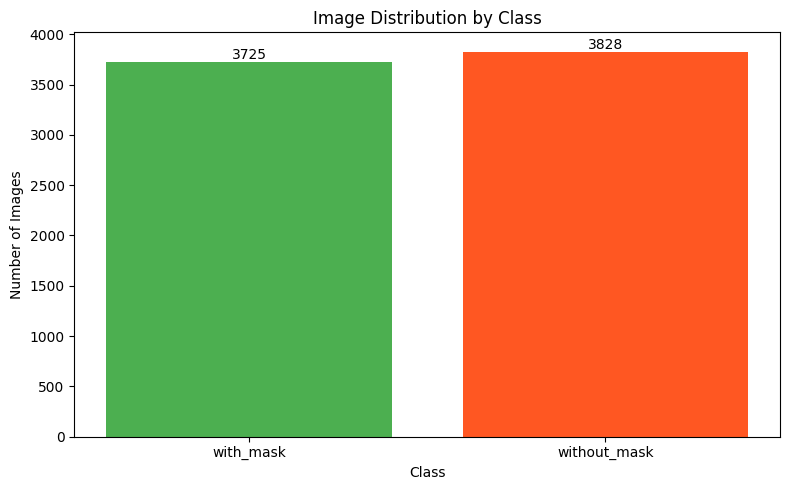

Class proportions: 
  with_mask: 49.32%
  without_mask: 50.68%

Result: The dataset is balanced (each class makes up 40% to 50%+ of the data).


In [12]:
class_counts = df["class_name"].value_counts().sort_index()

distribution = pd.DataFrame({
    "class_name": class_counts.index,
    "image_count": class_counts.values,
})

distribution["percentage"] = (
    distribution["image_count"] / distribution["image_count"].sum() * 100
).round(2)

display(distribution)

# Create the bar plot
plt.figure(figsize=(8, 5))
bars = plt.bar(
    distribution["class_name"],
    distribution["image_count"],
    color=['#4CAF50', '#FF5722']
)

plt.title("Image Distribution by Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.bar_label(bars)
plt.tight_layout()
plt.show()

# Check class balance based on percentages
min_percentage = distribution["percentage"].min()
max_percentage = distribution["percentage"].max()

print(f"Class proportions: ")
for idx, row in distribution.iterrows():
    print(f"  {row['class_name']}: {row['percentage']}%")

if min_percentage >= 40.0:
    print("\nResult: The dataset is balanced (each class makes up 40% to 50%+ of the data).")
else:
    print(f"\nResult: Noticeable class imbalance detected ({min_percentage:.1f}% vs {max_percentage:.1f}%).")

**Step 4 — Visualize sample images and their labels**

Since this is an image-classification task, there are no bounding boxes to draw. Instead, we will display sample images with their ground-truth class labels.

Inspect these samples for incorrect labels, irrelevant images, unusual crops, and images where the face is too small to identify the mask status. Those cases may require manual review.

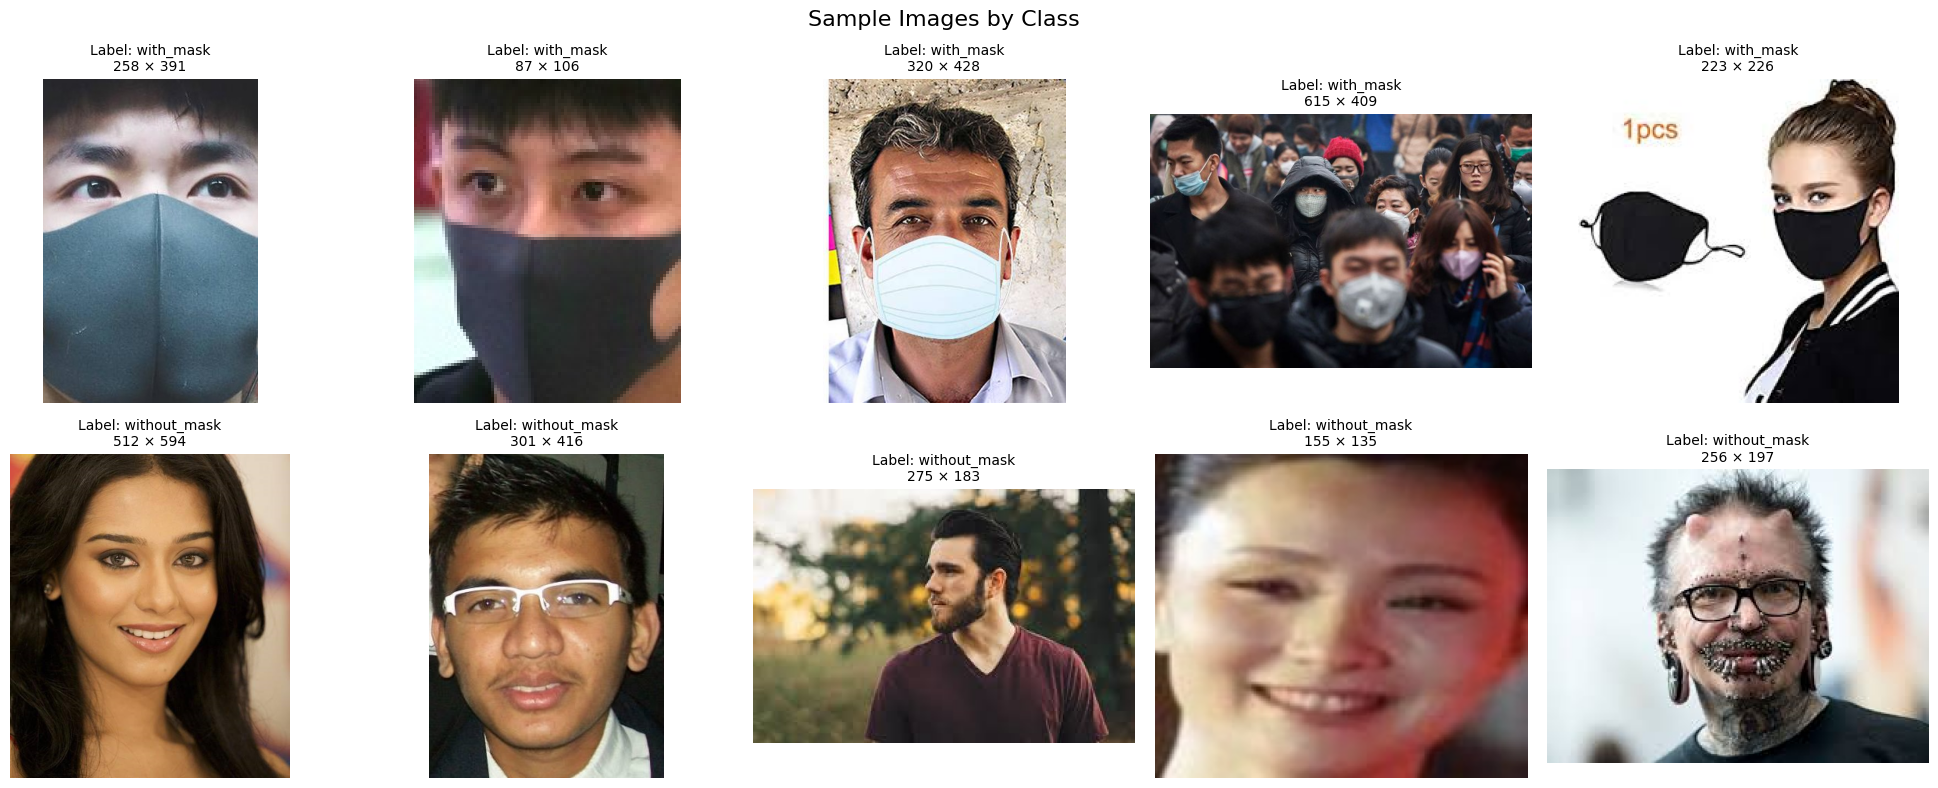

In [15]:
def show_samples(dataframe, samples_per_class=4):
    available_classes = sorted(dataframe["class_name"].unique())

    fig, axes = plt.subplots(
        len(available_classes),
        samples_per_class,
        figsize=(4 * samples_per_class, 4 * len(available_classes)),
        squeeze=False
    )

    for row, class_name in enumerate(available_classes):
        subset = dataframe[dataframe["class_name"] == class_name]

        selected = subset.sample(
            n=min(samples_per_class, len(subset)),
            random_state=SEED
        )

        for col in range(samples_per_class):
            ax = axes[row, col]
            ax.axis("off")

            if col >= len(selected):
                continue

            record = selected.iloc[col]

            with Image.open(record["filepath"]) as img:
                img = ImageOps.exif_transpose(img).convert("RGB")
                ax.imshow(img)

            ax.set_title(
                f"Label: {record['class_name']}\n"
                f"{record['width']} × {record['height']}",
                fontsize=10
            )

    plt.suptitle("Sample Images by Class", fontsize=16)
    plt.tight_layout()
    plt.show()

show_samples(df, samples_per_class=5)

**Step 5 — Check duplicates and suspicious image dimensions**

Duplicate files can cause data leakage if the same image ends up in both training and testing sets. We can identify exact duplicates by hashing their file contents.

Do not automatically delete duplicates based on filenames or image dimensions. If exact duplicates are found, review their labels and ensure duplicates cannot cross data-split boundaries.

In [16]:
import hashlib

def sha256_file(filepath):
    digest = hashlib.sha256()

    with open(filepath, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()

df["sha256"] = df["filepath"].map(sha256_file)

duplicate_mask = df.duplicated(subset="sha256", keep=False)
duplicates = df.loc[
    duplicate_mask
].sort_values("sha256")

print("Images involved in exact duplicates:", len(duplicates))

if not duplicates.empty:
    display(duplicates[["filename", "class_name", "sha256"]].head(20))

# Flag suspicious dimensions without automatically removing them.
df["min_dimension"] = df[["width", "height"]].min(axis=1)
df["max_dimension"] = df[["width", "height"]].max(axis=1)
df["aspect_ratio"] = df["width"] / df["height"]

suspicious = df[
    (df["min_dimension"] < 32) |
    (df["aspect_ratio"] < 0.25) |
    (df["aspect_ratio"] > 4.0)
]

print("Images flagged for dimension review:", len(suspicious))
display(suspicious[["filename", "class_name", "width", "height"]].head(20))

Images involved in exact duplicates: 574


,filename,class_name,sha256
1635,with_mask_2470.jpg,with_mask,018ac6cbc3e037ef5cf72f7b8af495f092b4af587cd381...
3510,with_mask_805.jpg,with_mask,018ac6cbc3e037ef5cf72f7b8af495f092b4af587cd381...
3472,with_mask_771.jpg,with_mask,0244298e25e5dcf3e719e1ef5162a6a145f06a94843d8b...
3553,with_mask_844.jpg,with_mask,0244298e25e5dcf3e719e1ef5162a6a145f06a94843d8b...
997,with_mask_1897.jpg,with_mask,029a6babac652e821caa0b55a1841ebfe2e1312ed107d4...
996,with_mask_1896.jpg,with_mask,029a6babac652e821caa0b55a1841ebfe2e1312ed107d4...
1723,with_mask_255.jpg,with_mask,04ab151775b998a47c7a35f67e43df38a4201df65f44b3...
3044,with_mask_386.jpg,with_mask,04ab151775b998a47c7a35f67e43df38a4201df65f44b3...
2659,with_mask_3392.jpg,with_mask,05515940fc00fc84ef7268db59490a4d103213e8555416...
2596,with_mask_3335.jpg,with_mask,05515940fc00fc84ef7268db59490a4d103213e8555416...


Images flagged for dimension review: 3


,filename,class_name,width,height
99,with_mask_1088.jpg,with_mask,26,37
262,with_mask_1234.jpg,with_mask,30,40
370,with_mask_1331.jpg,with_mask,29,84


**Step 6 — Define image augmentation**

We'll use horizontal flipping, mild brightness variation, small rotations, and modest zooming. These augmentations should be applied only to training images, not to validation or test images.

The augmentation layers expect RGB pixel values in the range 0–255. We'll convert images to that representation before applying augmentation. Avoid excessive rotation or zoom that removes the face from the image.

In [18]:
tf.random.set_seed(SEED)

data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(
            factor=0.04,
            fill_mode="reflect",
            seed=SEED
        ),
        layers.RandomZoom(
            height_factor=(-0.08, 0.08),
            width_factor=(-0.08, 0.08),
            fill_mode="reflect",
            seed=SEED
        ),
        layers.RandomBrightness(
            factor=0.15,
            value_range=(0, 255),
            seed=SEED
        ),
    ],
    name="data_augmentation"
)

print("Augmentation pipeline created.")

Augmentation pipeline created.


**Step 7 — Preview augmented images**

Review the previews to confirm that the mask remains visible and the image still represents the original class.

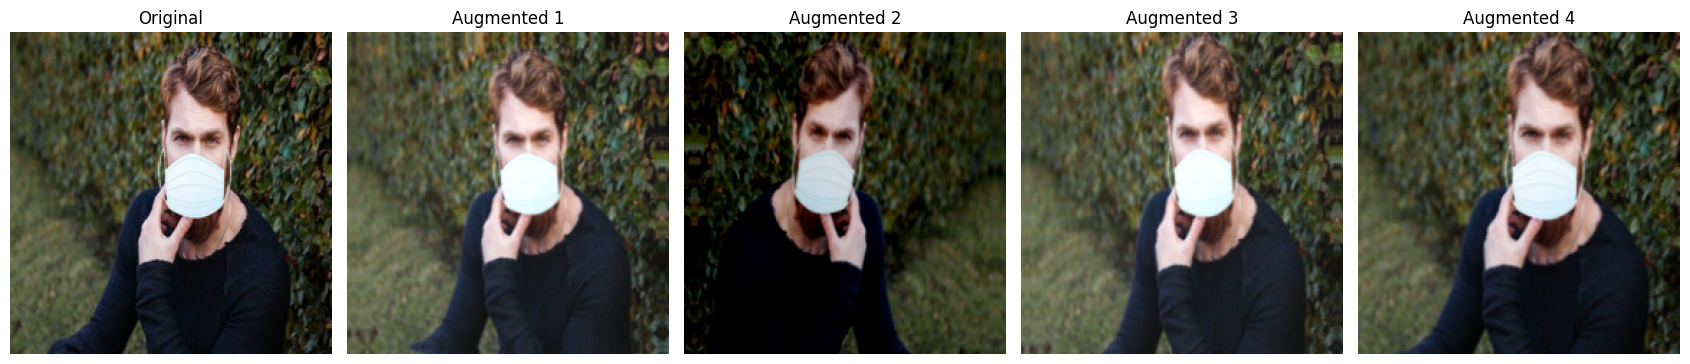

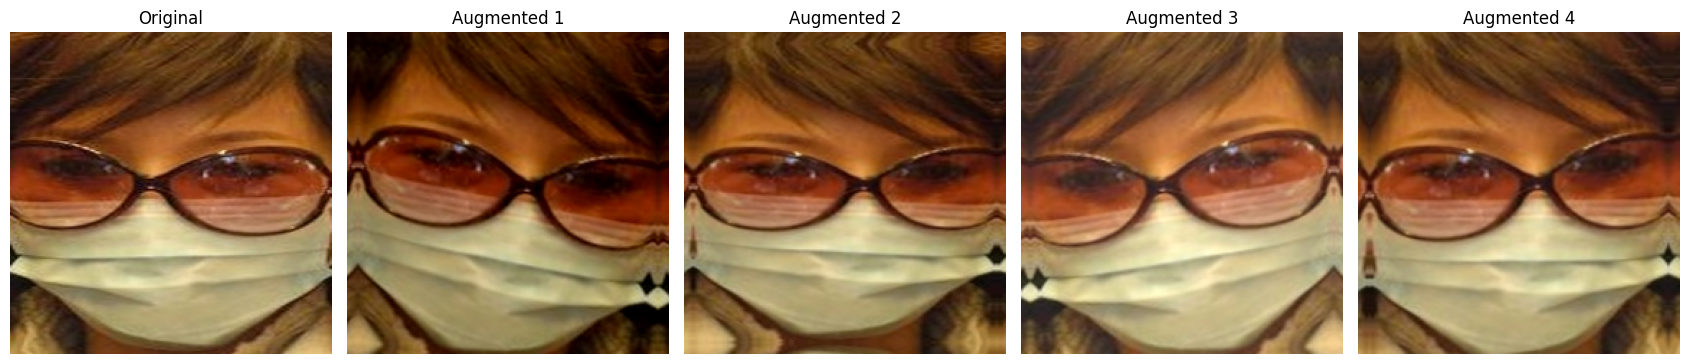

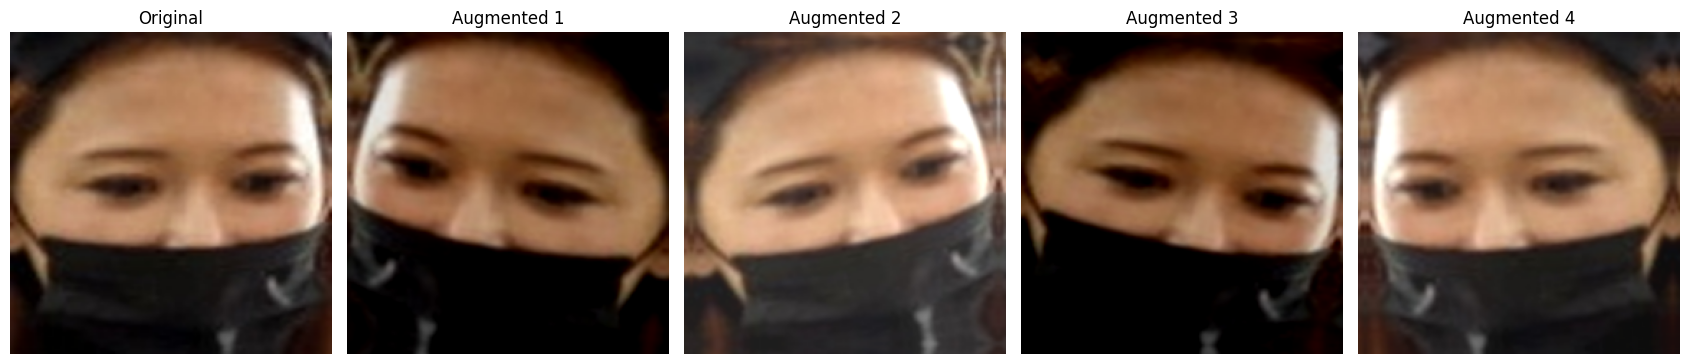

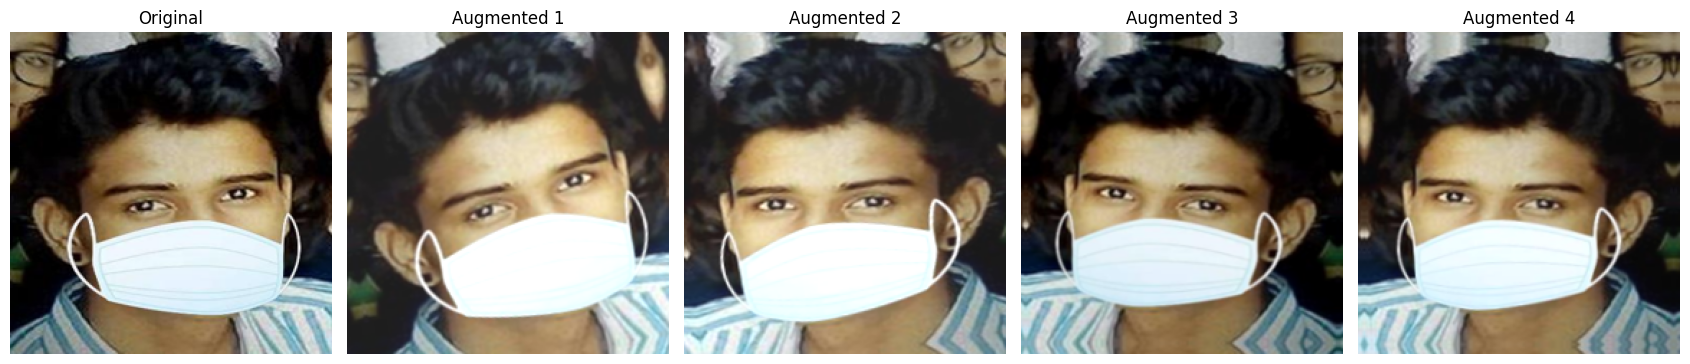

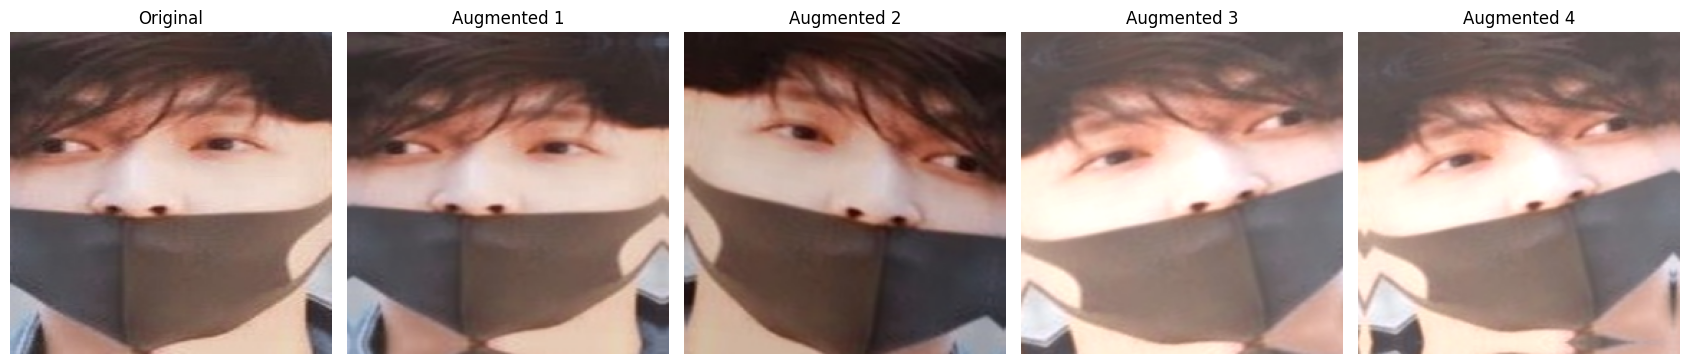

In [21]:
for i in range(5):
  sample_path = df.iloc[i]["filepath"]

  with Image.open(sample_path) as img:
      original = ImageOps.exif_transpose(img).convert("RGB").resize(
          (IMAGE_SIZE[1], IMAGE_SIZE[0])
      )

  original_array = np.asarray(original, dtype=np.float32)

  fig, axes = plt.subplots(1, 5, figsize=(17, 4))

  axes[0].imshow(original_array.astype(np.uint8))
  axes[0].set_title("Original")
  axes[0].axis("off")

  for i in range(1, 5):
      augmented = data_augmentation(
          tf.convert_to_tensor(original_array[None, ...]),
          training=True
      )[0].numpy()

      augmented = np.clip(augmented, 0, 255).astype(np.uint8)

      axes[i].imshow(augmented)
      axes[i].set_title(f"Augmented {i}")
      axes[i].axis("off")

  plt.tight_layout()
  plt.show()

**Step 9 — Limit the number of images if necessary**

For 7,553 images, we may not need to reduce the dataset. If memory or training time is limited, we can cap the number of original samples per class.

This caps the number of original images per class without generating synthetic images on disk. Augmentation will occur dynamically during training.

In [23]:
# None = use all valid samples.
# Example: 1500 = at most 1500 original images per class.
MAX_IMAGES_PER_CLASS = 1500

if MAX_IMAGES_PER_CLASS is None:
    df_prepared = df.copy()
else:
    df_prepared = (
        df.groupby("class_name", group_keys=False)
          .apply(
              lambda group: group.sample(
                  n=min(MAX_IMAGES_PER_CLASS, len(group)),
                  random_state=SEED
              ),
              include_groups=True
          )
          .reset_index(drop=True)
    )

print("Original valid images:", len(df))
print("Images selected:", len(df_prepared))
display(
    df_prepared["class_name"]
    .value_counts()
    .rename_axis("class_name")
    .reset_index(name="image_count")
)

Original valid images: 7553
Images selected: 3000


/tmp/ipykernel_3623/3075692226.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,class_name,image_count
0,with_mask,1500
1,without_mask,1500


**Step 9 — Save class names and the preparation manifest**

We will save the class mapping so training and inference use the same label order. We will also write a CSV manifest containing the image paths and labels.

Example configuration for the original two-class dataset:



```
 {
    "class_names": [
        "with_mask",
        "without_mask"
    ],
    "class_to_index": {
        "with_mask": 0,
        "without_mask": 1
    },
    "image_size": [224, 224],
    "color_mode": "RGB",
    "num_classes": 2,
    "dataset": "omkargurav/face-mask-dataset"
}
```

The actual configuration will be generated from the folders found in the copy of the dataset.

In [24]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Deterministic class-to-index mapping
class_names = sorted(df_prepared["class_name"].unique())

class_config = {
    "class_names": class_names,
    "class_to_index": {
        name: index for index, name in enumerate(class_names)
    },
    "image_size": list(IMAGE_SIZE),
    "color_mode": "RGB",
    "num_classes": len(class_names),
    "dataset": "omkargurav/face-mask-dataset"
}

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(class_config, f, indent=4)

manifest_path = OUTPUT_DIR / "image_manifest.csv"

df_prepared.to_csv(manifest_path, index=False)

print("Saved class configuration:", CONFIG_PATH.resolve())
print("Saved image manifest:", manifest_path.resolve())
print("\nClass configuration:")
print(json.dumps(class_config, indent=4))

Saved class configuration: /content/face_mask_prepared/class_names.json
Saved image manifest: /content/face_mask_prepared/image_manifest.csv

Class configuration:
{
    "class_names": [
        "with_mask",
        "without_mask"
    ],
    "class_to_index": {
        "with_mask": 0,
        "without_mask": 1
    },
    "image_size": [
        224,
        224
    ],
    "color_mode": "RGB",
    "num_classes": 2,
    "dataset": "omkargurav/face-mask-dataset"
}


**Step 10 — Final preparation summary**

What we have achieved

- Checked image readability and collected metadata.
- Measured the actual class distribution.
- Visualized sample images with their class labels.
- Identified potential duplicates and suspicious dimensions.
- Created an augmentation pipeline without modifying the original files.
- Added an optional per-class sample limit.
- Saved the class configuration and an image manifest.

In [25]:
print("=" * 50)
print("DATA CLEANING SUMMARY")
print("=" * 50)

print(f"Valid images before optional limiting: {len(df)}")
print(f"Images selected for preparation:       {len(df_prepared)}")
print(f"Unreadable images excluded:            {len(invalid_files)}")
print(f"Exact duplicate image rows:            {len(duplicates)}")
print(f"Classes:                               {class_names}")
print(f"Image size for model input:            {IMAGE_SIZE}")
print(f"Class config:                          {CONFIG_PATH}")
print(f"Image manifest:                        {manifest_path}")

print("\nSelected samples by class:")
print(df_prepared["class_name"].value_counts().to_string())

assert len(df_prepared) > 0, "No images remain after preparation."
assert all(
    name in class_names
    for name in df_prepared["class_name"].unique()
)

print("\nPreparation checks completed.")

DATA CLEANING SUMMARY
Valid images before optional limiting: 7553
Images selected for preparation:       3000
Unreadable images excluded:            0
Exact duplicate image rows:            574
Classes:                               ['with_mask', 'without_mask']
Image size for model input:            (224, 224)
Class config:                          face_mask_prepared/class_names.json
Image manifest:                        face_mask_prepared/image_manifest.csv

Selected samples by class:
class_name
with_mask       1500
without_mask    1500

Preparation checks completed.


### 3. Model Training and Evaluation

We’ll continue from the cleaned dataset and build a face-mask image classification model.

The notebook will use transfer learning with MobileNetV2, which is a CNN pretrained on ImageNet. We’ll split the dataset into training, validation, and testing sets, train the model, evaluate both classes, save the trained model, and implement predict_mask("image.jpg").

**Important:** This dataset supports image-level classification, not face detection. The model predicts whether an image belongs to with_mask or without_mask; it does not draw bounding boxes or independently classify multiple faces in one image.

**1. Prepare the training, validation, and testing sets**

We’ll use this split:
- 70% training: teach the model.
- 15% validation: monitor performance during training.
- 15% testing: evaluate the final model on unseen images.

In [26]:
# Check the dataset and define the classes
SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

tf.keras.utils.set_random_seed(SEED)

# The model is designed for binary classification.
CLASS_NAMES = ["with_mask", "without_mask"]

# Keep only the two required classes.
df_model = df_prepared[
    df_prepared["class_name"].isin(CLASS_NAMES)
].copy()

# Check that both classes exist.
found_classes = set(df_model["class_name"].unique())

if found_classes != set(CLASS_NAMES):
    raise ValueError(
        f"Expected classes {CLASS_NAMES}, but found {sorted(found_classes)}"
    )

# Remove duplicate file paths, if any.
df_model = df_model.drop_duplicates(subset="filepath").reset_index(drop=True)

# Assign numeric labels consistently:
# with_mask = 0
# without_mask = 1
class_to_index = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}

df_model["label"] = df_model["class_name"].map(class_to_index)

print("Total images:", len(df_model))
print("\nClass distribution:")
print(df_model["class_name"].value_counts())
print("\nClass mapping:", class_to_index)

Total images: 3000

Class distribution:
class_name
with_mask       1500
without_mask    1500
Name: count, dtype: int64

Class mapping: {'with_mask': 0, 'without_mask': 1}


In [28]:
# Split the dataset

# We’ll use stratified splitting so both classes
# are represented proportionally in all three sets.

# First split: 70% training, 30% temporary.
train_df, temp_df = train_test_split(
    df_model,
    test_size=0.30,
    random_state=SEED,
    stratify=df_model["label"]
)

# Second split: divide the temporary set equally.
# Final proportions: 70% training, 15% validation, 15% testing.
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Training images:   {len(train_df)} ({len(train_df) / len(df_model):.1%})")
print(f"Validation images: {len(val_df)} ({len(val_df) / len(df_model):.1%})")
print(f"Testing images:    {len(test_df)} ({len(test_df) / len(df_model):.1%})")

print("\nTraining class distribution:")
print(train_df["class_name"].value_counts())

print("\nValidation class distribution:")
print(val_df["class_name"].value_counts())

print("\nTesting class distribution:")
print(test_df["class_name"].value_counts())

Training images:   2100 (70.0%)
Validation images: 450 (15.0%)
Testing images:    450 (15.0%)

Training class distribution:
class_name
with_mask       1050
without_mask    1050
Name: count, dtype: int64

Validation class distribution:
class_name
with_mask       225
without_mask    225
Name: count, dtype: int64

Testing class distribution:
class_name
without_mask    225
with_mask       225
Name: count, dtype: int64


In [29]:
# Build the TensorFlow data pipeline
# This pipeline loads images, converts them to RGB,
# resizes them to 224 × 224, and creates batches.

AUTOTUNE = tf.data.AUTOTUNE

def load_image(filepath, label):
    image_bytes = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)

    label = tf.cast(label, tf.float32)
    return image, label


def create_dataset(dataframe, training=False):
    paths = dataframe["filepath"].astype(str).values
    labels = dataframe["label"].astype("float32").values

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)
    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("TensorFlow datasets created successfully.")

TensorFlow datasets created successfully.


**2. Build the CNN using transfer learning**

We’ll use MobileNetV2. It is lightweight compared with many larger CNN architectures and is a practical starting point for training in Google Colab.

The model will initially freeze the pretrained CNN layers and train a new classification head. Data augmentation is applied only during training.

How the output works:
- The sigmoid output is a probability between 0 and 1.

- A prediction below 0.5 means with_mask (label 0).

- A prediction of 0.5 or above means without_mask (label 1).


In [30]:
# Data augmentation for training images.
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.04),
    layers.RandomZoom(0.10),
    layers.RandomBrightness(
        factor=0.15,
        value_range=(0, 255)
    )
], name="data_augmentation")


# Load the pretrained CNN.
base_model = keras.applications.MobileNetV2(
    input_shape=(*IMAGE_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers during initial training.
base_model.trainable = False


# Build the complete classification model.
inputs = keras.Input(shape=(*IMAGE_SIZE, 3))

x = data_augmentation(inputs)

# Scale pixel values from [0, 255] to [-1, 1].
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1
)(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)

# One output neuron for binary classification.
outputs = layers.Dense(
    1,
    activation="sigmoid",
    name="mask_prediction"
)(x)

model = keras.Model(inputs, outputs, name="face_mask_classifier")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "face_mask_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mask_prediction (Dense)         │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [35]:
# We’ll save the best model based on validation loss
# and stop early if performance stops improving.
MODEL_PATH = Path("face_mask_classifier.keras")

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9859 - loss: 0.0367
Epoch 1: val_loss improved from None to 0.01585, saving model to face_mask_classifier.keras

Epoch 1: finished saving model to face_mask_classifier.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 124s 2s/step - accuracy: 0.9871 - loss: 0.0370 - val_accuracy: 0.9956 - val_loss: 0.0159 - learning_rate: 0.0010
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9936 - loss: 0.0243
Epoch 2: val_loss improved from 0.01585 to 0.01423, saving model to face_mask_classifier.keras

Epoch 2: finished saving model to face_mask_classifier.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 125s 2s/step - accuracy: 0.9924 - loss: 0.0276 - val_accuracy: 0.9956 - val_loss: 0.0142 - learning_rate: 0.0010
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9933 - loss: 0.0299
Epoch 3: val_loss improved from 0.01423 to 0.01387, saving model to face_mask_classifier.keras

Epoch 3: finished saving model to face_mask_classifier.keras
66/

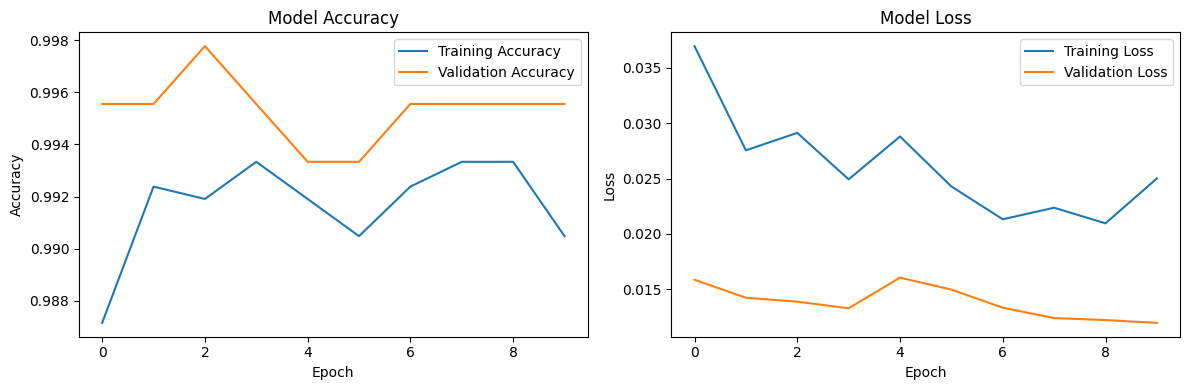

In [36]:
# Plot training performance
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training Accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation Accuracy")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training Loss")
axes[1].plot(history.history["val_loss"], label="Validation Loss")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

**3. Evaluate the model on the testing set**

The testing set was held out during training. We’ll calculate accuracy, precision, recall, F1-score, and a confusion matrix for both classes.

In [37]:
# Load the best saved model
best_model = keras.models.load_model(MODEL_PATH)

test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=1)
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy:.2%})")

15/15 ━━━━━━━━━━━━━━━━━━━━ 34s 2s/step - accuracy: 0.9933 - loss: 0.0151
Test Loss:     0.0151
Test Accuracy: 0.9933 (99.33%)


The classification report shows precision, recall, F1-score, and sample count for each class, along with macro and weighted averages.

- Precision: Of the images predicted as a class, how many were correct?

- Recall: Of the actual images in a class, how many did the model identify correctly?

- F1-score: The harmonic mean of precision and recall.

- Accuracy: The proportion of all test images classified correctly.

In [38]:
# Calculate precision, recall, and F1-score
# Collect the true labels from the testing DataFrame.
y_true = test_df["label"].to_numpy()

# Predict probabilities and convert them to class labels.
y_prob = best_model.predict(test_ds, verbose=1).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")

print(f"Macro Precision: {precision_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro Recall:    {recall_score(y_true, y_pred, average='macro', zero_division=0):.4f}")
print(f"Macro F1-score:  {f1_score(y_true, y_pred, average='macro', zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

15/15 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step
Accuracy:  0.9933
Macro Precision: 0.9934
Macro Recall:    0.9933
Macro F1-score:  0.9933

Classification Report:
              precision    recall  f1-score   support

   with_mask     1.0000    0.9867    0.9933       225
without_mask     0.9868    1.0000    0.9934       225

    accuracy                         0.9933       450
   macro avg     0.9934    0.9933    0.9933       450
weighted avg     0.9934    0.9933    0.9933       450



Interpretation for Confusion Matrix:

| Actual class   | Predicted `with_mask`                 | Predicted `without_mask`            |
| -------------- | ------------------------------------- | ----------------------------------- |
| `with_mask`    | Correctly identified mask images      | Mask images incorrectly classified  |
| `without_mask` | No-mask images incorrectly classified | Correctly identified no-mask images |

For a binary classifier, false positives and false negatives are important: an image of someone wearing a mask may be classified as unmasked, or vice versa.

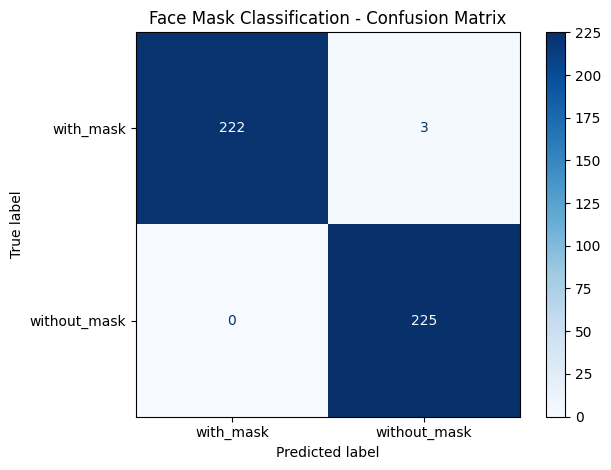

In [39]:
# Rows represent actual classes;
# columns represent predicted classes.

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

display.plot(cmap="Blues", values_format="d")
plt.title("Face Mask Classification - Confusion Matrix")
plt.tight_layout()
plt.show()

**4. Save the model and class configuration**

The trained model includes the preprocessing and augmentation layers. During inference, augmentation is automatically disabled.

In [40]:
# Save the best model.
best_model.save("face_mask_classifier.keras")

# Save the class mapping and input configuration.
config = {
    "class_names": CLASS_NAMES,
    "class_to_index": class_to_index,
    "image_size": list(IMAGE_SIZE),
    "threshold": 0.5,
    "positive_class_for_is_masked": "with_mask"
}

with open("face_mask_config.json", "w") as file:
    json.dump(config, file, indent=4)

# Save the test results for future reference.
test_results = {
    "test_loss": float(test_loss),
    "test_accuracy": float(test_accuracy),
    "test_precision_macro": float(
        precision_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "test_recall_macro": float(
        recall_score(y_true, y_pred, average="macro", zero_division=0)
    ),
    "test_f1_macro": float(
        f1_score(y_true, y_pred, average="macro", zero_division=0)
    )
}

with open("face_mask_evaluation.json", "w") as file:
    json.dump(test_results, file, indent=4)

print("Saved model: face_mask_classifier.keras")
print("Saved configuration: face_mask_config.json")
print("Saved evaluation: face_mask_evaluation.json")

Saved model: face_mask_classifier.keras
Saved configuration: face_mask_config.json
Saved evaluation: face_mask_evaluation.json


**5. Create the predict_mask("image.jpg") function**

This is the final prediction interface. It accepts an image path and returns whether the image is classified as showing a person wearing a mask.

In [41]:
# Load the model from disk.
mask_model = keras.models.load_model("face_mask_classifier.keras")


def predict_mask(image_path):
    """
    Predict whether an image belongs to the with_mask class.

    Parameters
    ----------
    image_path : str
        Path to the input image.

    Returns
    -------
    dict
        is_masked: Boolean prediction.
        predicted_class: Predicted class name.
        probability_without_mask: Model probability for without_mask.
    """
    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")

    # Load the image and convert it to RGB.
    with Image.open(image_path) as image:
        image = image.convert("RGB")
        image = image.resize(IMAGE_SIZE)

        image_array = np.asarray(image, dtype=np.float32)

    # Add the batch dimension: (224, 224, 3) -> (1, 224, 224, 3).
    image_array = np.expand_dims(image_array, axis=0)

    # The model returns the probability of class 1: without_mask.
    probability_without_mask = float(
        mask_model.predict(image_array, verbose=0)[0][0]
    )

    predicted_index = int(probability_without_mask >= 0.5)
    predicted_class = CLASS_NAMES[predicted_index]

    return {
        "is_masked": predicted_class == "with_mask",
        "predicted_class": predicted_class,
        "probability_without_mask": round(
            probability_without_mask, 4
        )
    }

In [42]:
uploaded = files.upload()

# Predict the first uploaded image.
image_path = next(iter(uploaded))

result = predict_mask(image_path)

print("is_masked:", str(result["is_masked"]).upper())
print("Predicted class:", result["predicted_class"])
print("Probability without mask:", result["probability_without_mask"])

Saving image.jpg to image.jpg
is_masked: TRUE
Predicted class: with_mask
Probability without mask: 0.0009


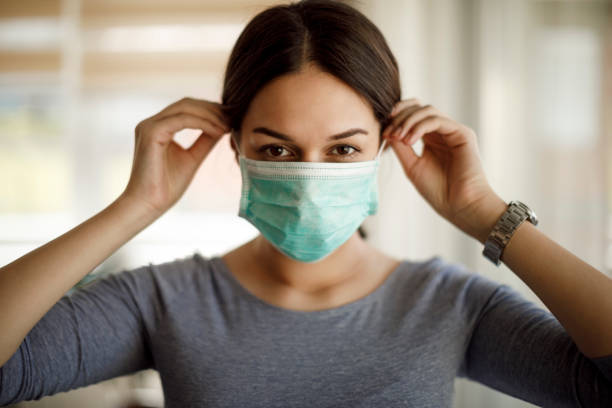

Example output:

```
is_masked: TRUE
Predicted class: with_mask
Probability without mask: 0.0312
```


Or, if the model predicts no mask:

```
is_masked: FALSE
Predicted class: without_mask
Probability without mask: 0.9725
```

These are illustrative examples, not actual evaluation results.

***Note:** If we restart the runtime, upload or mount the image again and ensure face_mask_classifier.keras is accessible. The model and configuration files should be downloaded or stored in Google Drive if you want to keep them beyond the temporary runtime.*

## Extra

The following cell use a separate copy of the dataset and independent variable names, so they will not modify the training, validation, testing, or trained model.

The goal is to explore the original images, understand how pixels represent colors, and see how an image becomes a numerical RGB array.

In [45]:
# Create a separate copy for visualization only.
exploration_df = df_prepared.copy(deep=True).reset_index(drop=True)

print("Dataset shape:", exploration_df.shape)
print("\nFirst 10 samples:")

# Use IPython's absolute display function to avoid name collisions with variables named 'display'
import IPython.display
IPython.display.display(exploration_df[["filename", "class_name", "filepath"]].head(10))

print("\nNumber of images per class:")
print(exploration_df["class_name"].value_counts())

Dataset shape: (3000, 11)

First 10 samples:


,filename,class_name,filepath
0,with_mask_1498.jpg,with_mask,/root/.cache/kagglehub/datasets/omkargurav/fac...
1,with_mask_682.jpg,with_mask,/root/.cache/kagglehub/datasets/omkargurav/fac...
2,with_mask_887.jpg,with_mask,/root/.cache/kagglehub/datasets/omkargurav/fac...
3,with_mask_3399.jpg,with_mask,/root/.cache/kagglehub/datasets/omkargurav/fac...
4,with_mask_2264.jpg,with_mask,/root/.cache/kagglehub/datasets/omkargurav/fac...
5,with_mask_1164.jpg,with_mask,/root/.cache/kagglehub/datasets/omkargurav/fac...
6,with_mask_366.jpg,with_mask,/root/.cache/kagglehub/datasets/omkargurav/fac...
7,with_mask_1436.jpg,with_mask,/root/.cache/kagglehub/datasets/omkargurav/fac...
8,with_mask_88.jpg,with_mask,/root/.cache/kagglehub/datasets/omkargurav/fac...
9,with_mask_2847.jpg,with_mask,/root/.cache/kagglehub/datasets/omkargurav/fac...



Number of images per class:
class_name
with_mask       1500
without_mask    1500
Name: count, dtype: int64


An image dataset consists of individual image files. Each file contains pixel values, while the dataset associates each image with a class label.

The class label is the expected category assigned to each image. The model learns patterns from the pixels to predict that category for new images.

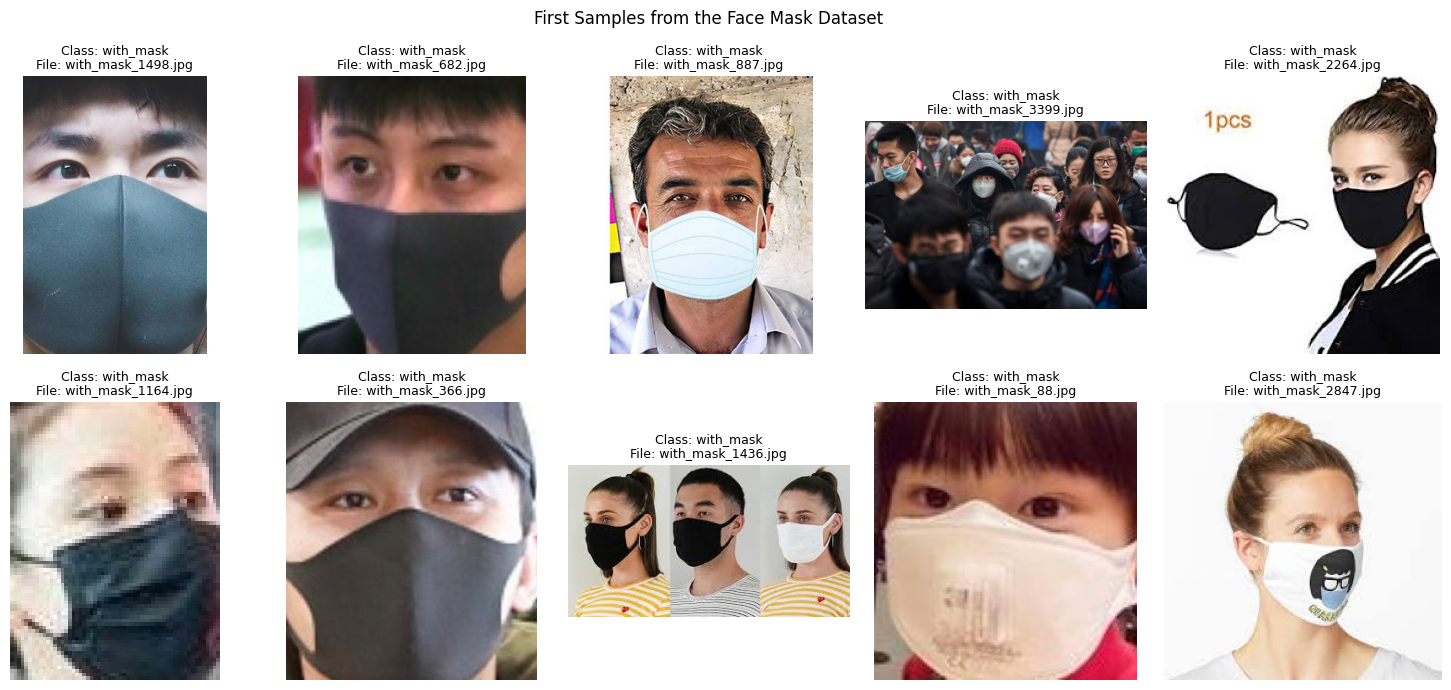

In [46]:
# Display the first 10 images from the separate exploration copy.
sample_count = min(10, len(exploration_df))

fig, axes = plt.subplots(2, 5, figsize=(15, 7))
axes = axes.flatten()

for i in range(sample_count):
    sample = exploration_df.iloc[i]

    with Image.open(sample["filepath"]) as img:
        rgb_image = img.convert("RGB")
        axes[i].imshow(rgb_image)

    axes[i].set_title(
        f"Class: {sample['class_name']}\n"
        f"File: {sample['filename']}",
        fontsize=9
    )
    axes[i].axis("off")

for i in range(sample_count, len(axes)):
    axes[i].axis("off")

plt.suptitle("First Samples from the Face Mask Dataset")
plt.tight_layout()
plt.show()

A digital image is made of a grid of pixels. Each pixel stores information about the color at one location in the image.

For an RGB image, each pixel has three color-channel values:

7777f2_e9c0c7ca9ab449a78d277d20dd871fef~mv2.avif

In standard 8-bit RGB images, each channel ranges from 0 to 255.

- (255, 0, 0) represents pure red.
- (0, 255, 0) represents pure green.
- (0, 0, 255) represents pure blue.
- (255, 255, 255) represents white.
- (0, 0, 0) represents black.

Different combinations of these three values produce a wide range of colors.

In [47]:
# Select the first sample without changing the original DataFrame.
pixel_sample = exploration_df.iloc[0]

with Image.open(pixel_sample["filepath"]) as img:
    original_image = img.copy()
    rgb_image = img.convert("RGB")

    # Convert the RGB image into a NumPy array.
    rgb_array = np.array(rgb_image)

print("Filename:", pixel_sample["filename"])
print("Class:", pixel_sample["class_name"])
print("Original image mode:", original_image.mode)
print("RGB image mode:", rgb_image.mode)
print("Image dimensions (width, height):", rgb_image.size)
print("RGB array shape:", rgb_array.shape)
print("Array data type:", rgb_array.dtype)
print("Minimum channel value:", rgb_array.min())
print("Maximum channel value:", rgb_array.max())

Filename: with_mask_1498.jpg
Class: with_mask
Original image mode: RGB
RGB image mode: RGB
Image dimensions (width, height): (258, 391)
RGB array shape: (391, 258, 3)
Array data type: uint8
Minimum channel value: 13
Maximum channel value: 255


For an image with height \(H\) and width \(W\), the RGB array normally has shape:

$$(H, W, 3)$$

The three dimensions represent:
1. Image height in pixels.
2. Image width in pixels.
3. The three color channels: red, green, and blue.

For example, an image with dimensions 480 × 640 has an RGB array with shape (480, 640, 3).

**Important:** Converting an image to RGB does not mean every pixel becomes a new color. It means the image is represented using three color channels. Images originally stored in grayscale, palette-based (P), or RGBA formats can be converted to RGB for consistent processing.

In [48]:
# Display a 5 x 5 pixel region from the top-left corner.
pixel_region = rgb_array[:5, :5, :]

print("RGB values for the top-left 5 x 5 pixel region:")
print(pixel_region)

# Display the first pixel's RGB values.
first_pixel = rgb_array[0, 0]

print("\nFirst pixel at coordinate (row=0, column=0):")
print("Red:", int(first_pixel[0]))
print("Green:", int(first_pixel[1]))
print("Blue:", int(first_pixel[2]))
print("RGB tuple:", tuple(int(value) for value in first_pixel))

RGB values for the top-left 5 x 5 pixel region:
[[[39 40 44]
  [39 40 44]
  [39 40 44]
  [40 41 45]
  [40 41 45]]

 [[39 40 44]
  [38 39 43]
  [39 40 44]
  [40 41 45]
  [40 41 45]]

 [[39 40 44]
  [39 40 44]
  [39 40 44]
  [39 40 44]
  [39 40 44]]

 [[40 41 45]
  [39 40 44]
  [39 40 44]
  [39 40 44]
  [39 40 44]]

 [[39 40 44]
  [39 40 44]
  [39 40 44]
  [38 39 43]
  [38 39 43]]]

First pixel at coordinate (row=0, column=0):
Red: 39
Green: 40
Blue: 44
RGB tuple: (39, 40, 44)


Each entry in the array represents one pixel. For example:

```
[[[120,  80,  60], [121,  81,  61], ...]]
```


The values represent the intensity of the red, green, and blue channels at each pixel location.

An RGB image can be separated into three grayscale channel images. Each grayscale image displays the intensity of one color channel.

Brighter regions in a channel image indicate higher intensity in that channel. Darker regions indicate lower intensity. The three channels combine to reconstruct the original color image.

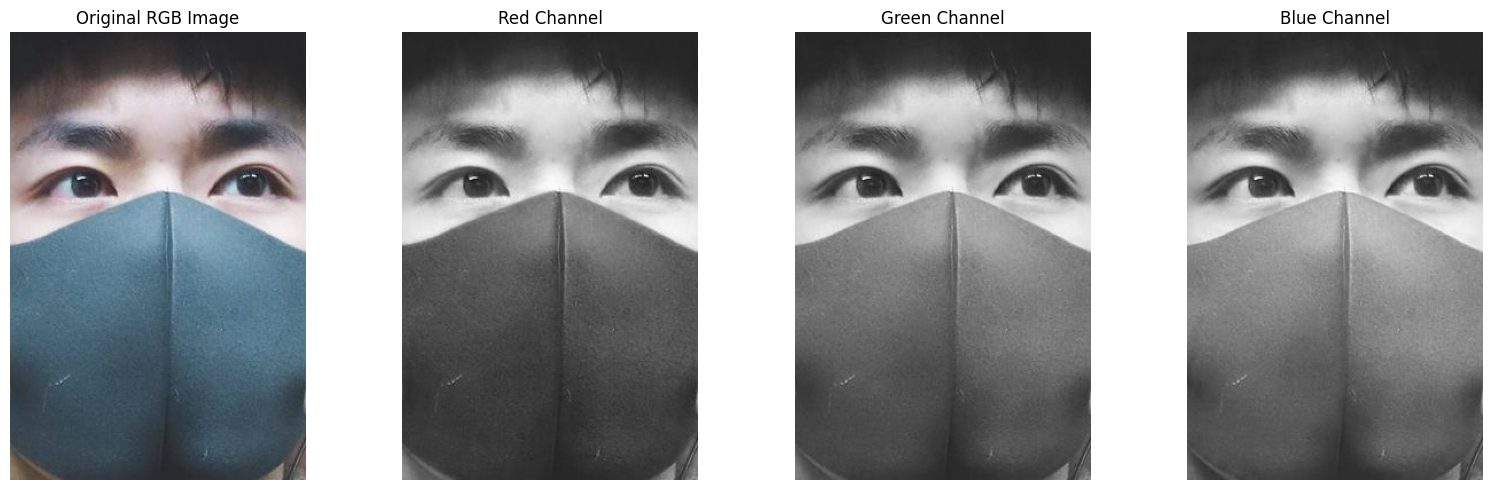

In [49]:
red_channel = rgb_array[:, :, 0]
green_channel = rgb_array[:, :, 1]
blue_channel = rgb_array[:, :, 2]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

axes[0].imshow(rgb_array)
axes[0].set_title("Original RGB Image")

axes[1].imshow(red_channel, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Red Channel")

axes[2].imshow(green_channel, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Green Channel")

axes[3].imshow(blue_channel, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Blue Channel")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

At normal viewing size, individual pixels are difficult to distinguish. This example enlarges a small image region so the pixel grid becomes visible.

Each small square represents a pixel. The image is made of many such squares, and neighboring pixels with similar colors create the visual appearance of continuous objects, edges, and textures.

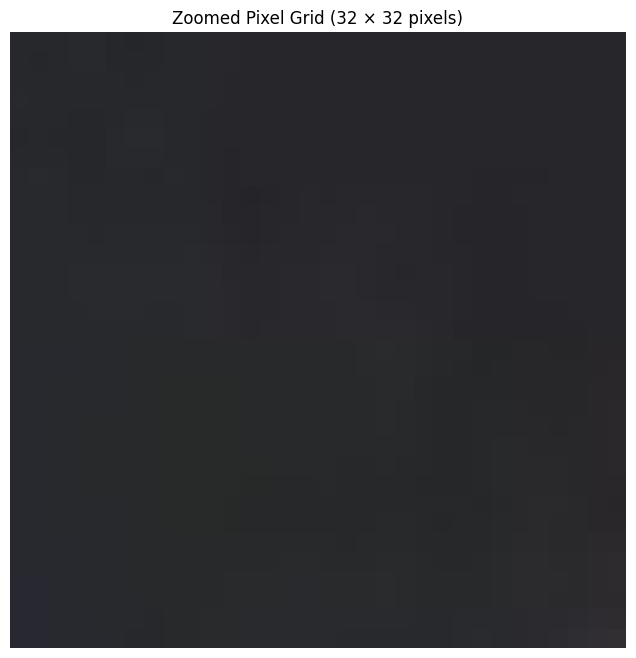

In [50]:
# Use a small region so the enlarged pixels remain easy to inspect.
zoom_size = min(32, rgb_array.shape[0], rgb_array.shape[1])
zoom_region = rgb_array[:zoom_size, :zoom_size, :]

plt.figure(figsize=(8, 8))
plt.imshow(zoom_region, interpolation="nearest")
plt.title(f"Zoomed Pixel Grid ({zoom_size} × {zoom_size} pixels)")
plt.axis("off")
plt.show()

The trained model expects images with dimensions 224 × 224 × 3. This cell resizes a separate sample to that shape, just as the prediction function does.

Original RGB array shape: (391, 258, 3)
Resized image array shape: (224, 224, 3)
Model input batch shape: (1, 224, 224, 3)
Model input data type: float32


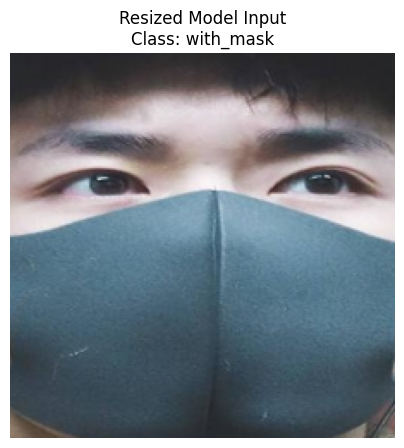

In [51]:
model_input_sample = exploration_df.iloc[0]

with Image.open(model_input_sample["filepath"]) as img:
    model_rgb_image = img.convert("RGB").resize(IMAGE_SIZE)

model_input_array = np.asarray(
    model_rgb_image,
    dtype=np.float32
)

# Add a batch dimension, matching the model's expected input shape.
model_input_batch = np.expand_dims(model_input_array, axis=0)

print("Original RGB array shape:", rgb_array.shape)
print("Resized image array shape:", model_input_array.shape)
print("Model input batch shape:", model_input_batch.shape)
print("Model input data type:", model_input_batch.dtype)

plt.figure(figsize=(5, 5))
plt.imshow(model_input_array.astype(np.uint8))
plt.title(f"Resized Model Input\nClass: {model_input_sample['class_name']}")
plt.axis("off")
plt.show()

The extra 1 represents the batch size: one image being passed to the model.

The model then applies its own preprocessing and CNN layers to extract useful visual features, such as edges, textures, and patterns associated with wearing a mask. The final classification layer uses those learned features to predict with_mask or without_mask.

**One distinction:** this exploration cell displays raw RGB values in the range 0–255. In the trained model, the Rescaling layer transforms these values to approximately -1 to 1 before they enter MobileNetV2. The exploration cells do not change the model or its training data.

# Recap

## 1. Project Summary

In this project, we developed an image classification system to predict whether an image belongs to one of two classes: `with_mask` or `without_mask`.

We used **MobileNetV2**, a pretrained Convolutional Neural Network (CNN), as the feature extractor. Transfer learning allowed us to reuse visual features learned from a large image dataset and train a classification layer for our face mask dataset.

The project covered:
- Exploring the dataset and inspecting image samples.
- Converting images into RGB pixel arrays.
- Splitting the dataset into training, validation, and testing sets.
- Applying data augmentation to improve generalization.
- Training and saving the model.
- Evaluating the model using accuracy, precision, recall, F1-score, and a confusion matrix.
- Creating `predict_mask("image.jpg")` for single-image prediction.

The system returns a Boolean result indicating whether the image is classified as showing a person wearing a mask.

## 2. Limitations

### Image-level classification

The model classifies the entire image into one of two categories. It does not locate individual faces or identify where a mask appears in the image.

If an image contains multiple people, the model still produces only one prediction for the entire image. Its prediction may not accurately describe every person in the scene.

### Limited class coverage

The current model supports only `with_mask` and `without_mask`. It cannot explicitly distinguish correctly worn masks from incorrectly worn masks, such as masks covering the mouth but leaving the nose exposed.

### Dataset quality and generalization

The model's performance depends on the quality, diversity, and class distribution of its training data. It may perform poorly on unfamiliar lighting conditions, unusual camera angles, low-resolution images, occlusions, or images from different environments.

The model may also learn unintended correlations in the dataset rather than features that reliably indicate mask usage.

### Photoshopped or manipulated images

The model was not specifically trained to detect digitally added, edited, or photoshopped masks. It may classify such images incorrectly because it evaluates visual patterns rather than verifying whether a mask is genuine.

### Evaluation limitations

High accuracy on the test set does not guarantee reliable performance in real-world conditions. The test set must be independent of the training data, and evaluation should account for duplicate images, class imbalance, and differences between training and real-world images.

## 3. Further Improvements and Other Variants

### Variant A: Multi-class Image Classification

The classification task can be extended to distinguish more than two categories, provided the dataset contains suitable labeled examples.

Possible classes include:

- `with_mask`: A mask is worn correctly.
- `without_mask`: No mask is worn.
- `mask_weared_incorrect`: A mask is worn incorrectly.

A new model would need to be trained using a dataset containing all required classes. The output layer and loss function would also need to be adapted for multi-class classification.

This approach still predicts a class for the entire image. It does not automatically locate individual faces or assign separate predictions to multiple people.

### Variant B: Detecting Incorrectly Worn Masks

To distinguish correct mask usage from incorrect mask usage, the model needs examples that clearly represent the relevant categories.

A more specialized classifier could learn to distinguish:
- Masks covering both the nose and mouth.
- Masks covering only the mouth.
- Masks worn below the nose or chin.
- Faces without masks.

However, a model trained only on whole-image labels may struggle when an image contains multiple people. A face detection stage followed by a mask classifier could provide individual predictions for each detected face.

### Variant C: Detecting Photoshopped or Artificially Added Masks

Detecting manipulated images is a different problem from ordinary mask classification.

A dedicated model could be trained on both authentic and manipulated examples, including masks added through image editing or generated imagery. The model might learn visual inconsistencies such as unnatural edges, lighting mismatches, texture differences, or blending artifacts.

However, these clues are not definitive proof of manipulation. Reliable detection requires a representative dataset containing both genuine and manipulated images, and performance may decline when new editing methods are introduced.

### Variant D: Object Detection Using YOLO

Unlike image classification, **object detection identifies both what an object is and where it appears in an image**.

For example, an image might contain several people:
- One person wearing a mask correctly in the foreground.
- One person without a mask near the center.
- Another person wearing a mask incorrectly in the background.

An image classifier returns one prediction for the entire image. An object detector can return multiple detections, each with a class label, confidence score, and bounding box.

A YOLO-based model could detect faces or people and classify their mask status, depending on the classes and annotations used to train it.

Object detection requires a dataset with **bounding-box annotations**. Each annotated object needs a class label and coordinates describing its position in the image. An image-level folder label alone is insufficient for standard supervised object detection training.

For example, a bounding box identifies an object's approximate position using coordinates such as its left and top edges, width, and height. This allows the model to learn not only what the object looks like, but also where it is located.

## 4. Comparison of the Approaches

| Approach | Main output | Required labels | Suitable use case |
|---|---|---|---|
| Binary image classification | One of two image-level classes | Image-level class labels | Determine whether an image belongs to `with_mask` or `without_mask` |
| Multi-class image classification | One of several image-level classes | Image-level class labels for every category | Classify images into correct mask, incorrect mask, and no mask categories |
| Face detection + classification | Individual face locations and mask predictions | Face bounding boxes and mask class labels, depending on the training approach | Evaluate mask usage for multiple faces in one image |
| YOLO object detection | Multiple class labels and bounding boxes | Bounding-box coordinates and object class labels | Locate and classify multiple faces or people in a scene |

## 5. Conclusion

This project demonstrates a practical application of CNNs and transfer learning for image classification. It provides a foundation for understanding how image pixels become model inputs, how a pretrained network learns task-specific features, and how classification performance can be evaluated.

The next step depends on the intended application. For a simple image-level prediction, the current classifier is sufficient as a starting point. For recognizing incorrect mask usage on individual people, face detection combined with classification may be more suitable. For locating multiple objects directly, a properly annotated dataset and an object detection model such as YOLO would be a more appropriate direction.